# Single random circuit: generate -> optimize -> compare

Run this notebook from the **project root** (the folder that contains `src/`).
All logic lives in `src/single_run.py`; this notebook only sets parameters and shows results.

In [113]:
import os, sys
sys.path.insert(0, os.getcwd())   # so `import src...` works from the project root

%matplotlib inline
from src.single_run import run_single, print_report, plot_single, draw_circuits

## 1. Parameters
Same seed + same parameters always gives the same circuit.
Keep `qubits` at 10 or below so equivalence can be verified.

In [114]:
QUBITS = 5
GATES = 120
REDUNDANCY = 0.8   # 0 = fully random, higher = more removable patterns
SEED = 6

## 2. Run and report

In [115]:
result = run_single(QUBITS, GATES, REDUNDANCY, SEED)
print_report(result, max_diagram_gates=0)   # text diagrams off; drawn graphically below


Circuit: 5 qubits, target 120 gates (actual 120), redundancy 0.8, seed 6
Optimizer rounds: 3
Equivalent to original - ours: yes
Equivalent to original - Qiskit: yes

Metrics
                   Original    Ours  Qiskit
Gate count            120.0   30.00   24.00
Circuit depth          55.0   16.00   11.00
Weighted cost         354.0  102.00   70.00
Two-qubit gates        29.0   13.00   11.00
T-count                29.0    5.00    1.00
SWAP count             12.0    2.00    0.00
Compile time (ms)         -    4.33    6.33

Reduction vs original (%)
                 Ours  Qiskit
Gate count       75.0    80.0
Circuit depth    70.9    80.0
Weighted cost    71.2    80.2
Two-qubit gates  55.2    62.1
T-count          82.8    96.6
SWAP count       83.3   100.0

Original: 120 gates, diagram skipped (limit 0)

Ours: 30 gates, diagram skipped (limit 0)

Qiskit: 24 gates, diagram skipped (limit 0)


## 3. Circuit drawings
Circuits above `max_gates` are skipped because they become unreadable.

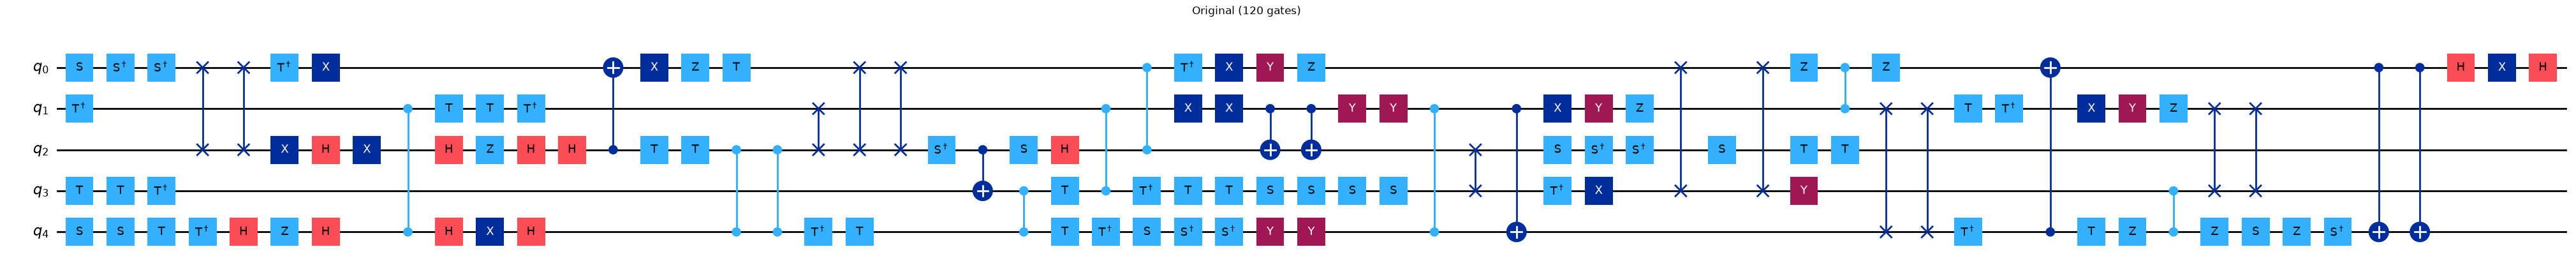

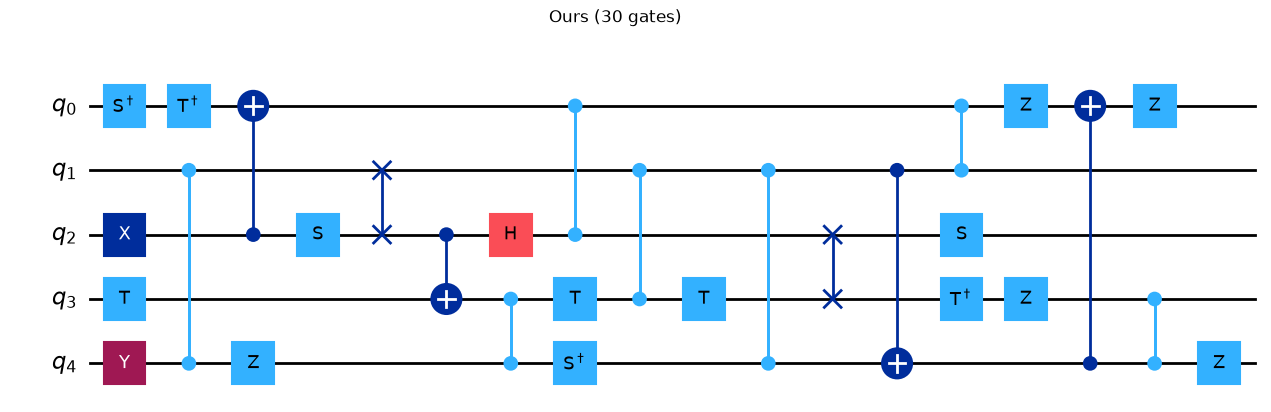

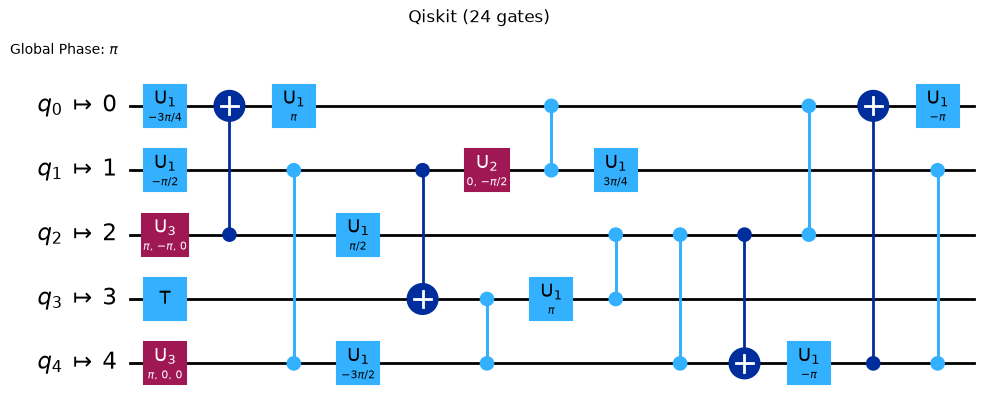

In [116]:
figs = draw_circuits(result, max_gates=200, fold=-1, save_dir="results/plots") 
# fold is the maximum number of columns the drawing shows on one row before it wraps to the next row. fold = -1 turns wrapping off.

## 4. Charts

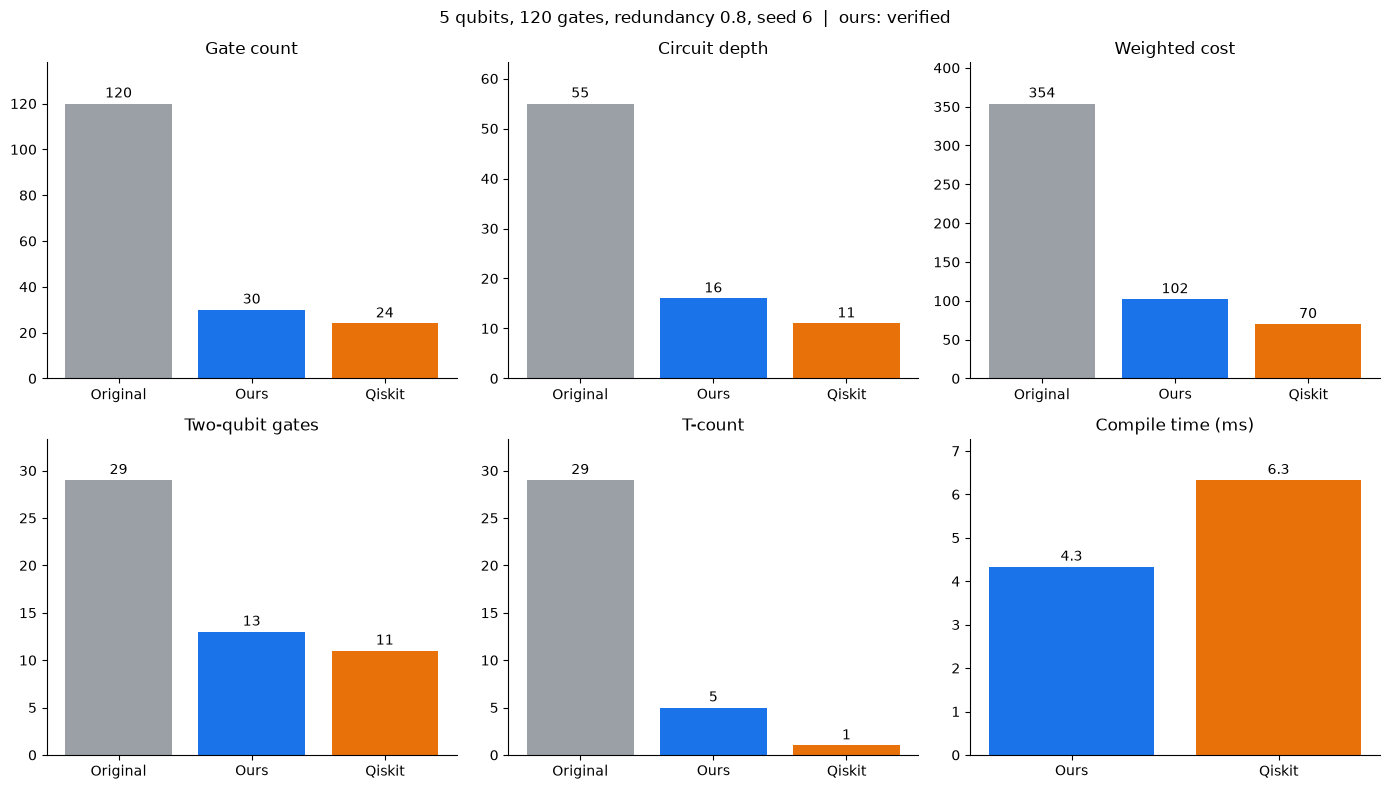

In [117]:
fig = plot_single(result, save_path="results/plots/single_latest.png")

## 5. Tables

In [118]:
result["table"].round(2)

,Original,Ours,Qiskit
Gate count,120.0,30.00,24.00
Circuit depth,55.0,16.00,11.00
Weighted cost,354.0,102.00,70.00
Two-qubit gates,29.0,13.00,11.00
T-count,29.0,5.00,1.00
SWAP count,12.0,2.00,0.00
Compile time (ms),NaN,4.33,6.33


In [119]:
result["reduction"].round(1)

,Ours,Qiskit
Gate count,75.0,80.0
Circuit depth,70.9,80.0
Weighted cost,71.2,80.2
Two-qubit gates,55.2,62.1
T-count,82.8,96.6
SWAP count,83.3,100.0


## 6. Raw circuits (optional)
`result["circuits"]` holds the `Original`, `Ours` and `Qiskit` circuits as Qiskit objects.

In [120]:
from qiskit import qasm2
print(qasm2.dumps(result["circuits"]["Ours"]))

OPENQASM 2.0;
include "qelib1.inc";
qreg q[5];
y q[4];
sdg q[0];
x q[2];
tdg q[0];
cx q[2],q[0];
s q[2];
cz q[1],q[4];
z q[4];
t q[3];
swap q[2],q[1];
cx q[2],q[3];
cz q[3],q[4];
t q[3];
cz q[3],q[1];
t q[3];
sdg q[4];
h q[2];
cz q[0],q[2];
swap q[2],q[3];
tdg q[3];
z q[3];
cz q[4],q[1];
cx q[1],q[4];
cz q[0],q[1];
z q[0];
cx q[4],q[0];
cz q[4],q[3];
z q[4];
s q[2];
z q[0];
